PM2.5 REVIEW
Q1: 2.88, median: 5.84, Q3: 13.48
Lower IQR fence: -13.02
Upper IQR fence: 29.38
Negative readings: 0
Readings below lower fence: 0
Readings above upper fence: 544,591
Recommendation: investigate negative values and IQR flags;
do not remove high values solely because they exceed the fence.

Total rows missing RH: 32,499
Missing-RH rows with valid coordinates: 32,499
Missing-RH rows without valid coordinates: 0
Coordinate pairs with missing RH: 18

Neighborhood counts within 1 km:


,latitude,longitude,missing_at_coordinate,nearby_readings,nearby_missing_rh,nearby_known_sensors
9,52.226,5.200,2,94823,26379,7
13,52.232,5.202,1296,87238,18770,7
14,52.233,5.193,8,87214,18770,6
10,52.228,5.193,1978,87217,18770,7
12,52.232,5.196,15486,87214,18770,6
5,52.218,5.188,1,29937,7617,5
6,52.218,5.196,7609,20732,7612,3
17,52.388,4.957,5024,37381,6060,7
16,52.387,4.955,1036,37381,6060,7
3,52.212,5.162,7,116219,26,5


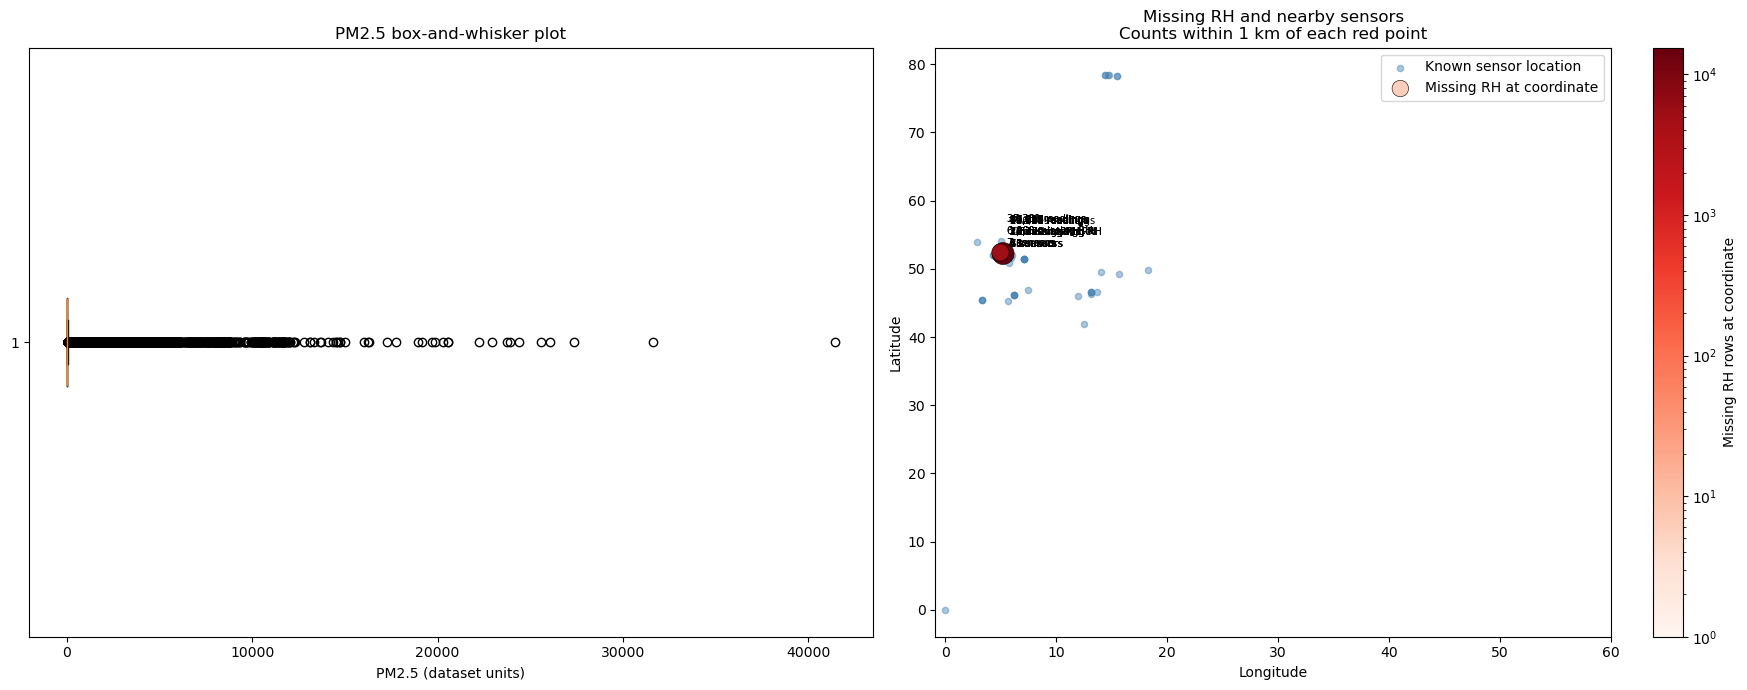

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from sklearn.neighbors import BallTree
from IPython.display import display

path = r"../data/data_sensors.parquet"  # relative to notebooks/
radius_km = 1.0  # Change this to explore a larger or smaller area

columns = ["kit_id", "pm25_raw", "rh", "latitude", "longitude"]
df = pd.read_parquet(path, columns=columns)

df["kit_id"] = df["kit_id"].astype("string")
for col in ["pm25_raw", "rh", "latitude", "longitude"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.replace([np.inf, -np.inf], np.nan)

# ------------------------------------------------------------
# 1. PM2.5 box plot and review recommendations
# ------------------------------------------------------------
pm = df["pm25_raw"].dropna()

if pm.empty:
    raise ValueError("No finite PM2.5 readings found.")

q1, median, q3 = np.percentile(pm, [25, 50, 75])
iqr = q3 - q1
lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr

negative_count = (pm < 0).sum()
low_count = (pm < lower_fence).sum()
high_count = (pm > upper_fence).sum()

print("PM2.5 REVIEW")
print(f"Q1: {q1:.2f}, median: {median:.2f}, Q3: {q3:.2f}")
print(f"Lower IQR fence: {lower_fence:.2f}")
print(f"Upper IQR fence: {upper_fence:.2f}")
print(f"Negative readings: {negative_count:,}")
print(f"Readings below lower fence: {low_count:,}")
print(f"Readings above upper fence: {high_count:,}")
print("Recommendation: investigate negative values and IQR flags;")
print("do not remove high values solely because they exceed the fence.\n")

# ------------------------------------------------------------
# 2. Missing RH and nearby sensor readings
# ------------------------------------------------------------
df["missing_rh"] = df["rh"].isna()
missing = df[df["missing_rh"]]

valid_coords = (
    df["latitude"].between(-90, 90)
    & df["longitude"].between(-180, 180)
)
located = df[valid_coords].copy()

print(f"Total rows missing RH: {len(missing):,}")
print(f"Missing-RH rows with valid coordinates: {located['missing_rh'].sum():,}")
print(f"Missing-RH rows without valid coordinates: "
      f"{len(missing) - located['missing_rh'].sum():,}")

# One row per exact coordinate pair. Keep the known sensor IDs so
# that a sensor appearing at several nearby coordinates counts once.
locations = (
    located.groupby(["latitude", "longitude"], as_index=False)
    .agg(
        total_readings=("rh", "size"),
        missing_rh_readings=("missing_rh", "sum"),
        sensor_ids=("kit_id", lambda ids: set(ids.dropna())),
    )
)

missing_locations = locations[locations["missing_rh_readings"] > 0].copy()
print(f"Coordinate pairs with missing RH: {len(missing_locations):,}")

# For each missing-RH coordinate, count all readings and unique known
# sensors within radius_km. Neighborhoods can overlap.
region_rows = []

if not locations.empty:
    coords_rad = np.radians(locations[["latitude", "longitude"]].to_numpy())
    tree = BallTree(coords_rad, metric="haversine")

    for _, center in missing_locations.iterrows():
        center_rad = np.radians([[center["latitude"], center["longitude"]]])
        indices = tree.query_radius(center_rad, r=radius_km / 6371.0088)[0]
        nearby = locations.iloc[indices]

        nearby_sensors = set().union(*nearby["sensor_ids"].tolist())
        region_rows.append({
            "latitude": center["latitude"],
            "longitude": center["longitude"],
            "missing_at_coordinate": int(center["missing_rh_readings"]),
            "nearby_readings": int(nearby["total_readings"].sum()),
            "nearby_missing_rh": int(nearby["missing_rh_readings"].sum()),
            "nearby_known_sensors": len(nearby_sensors),
        })

regions = pd.DataFrame(region_rows)

if not regions.empty:
    print(f"\nNeighborhood counts within {radius_km:g} km:")
    display(regions.sort_values("nearby_missing_rh", ascending=False))

# ------------------------------------------------------------
# 3. Plots
# ------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

axes[0].boxplot(pm, vert=False, whis=1.5)
axes[0].set_title("PM2.5 box-and-whisker plot")
axes[0].set_xlabel("PM2.5 (dataset units)")

# Blue: coordinate pairs with at least one known sensor ID.
sensor_locations = locations[locations["sensor_ids"].map(len) > 0]
axes[1].scatter(
    sensor_locations["longitude"], sensor_locations["latitude"],
    color="steelblue", s=20, alpha=0.45, label="Known sensor location"
)

# Red: coordinate pairs with at least one missing RH reading.
if not missing_locations.empty:
    counts = missing_locations["missing_rh_readings"]
    sizes = 30 + 220 * np.sqrt(counts / counts.max())

    points = axes[1].scatter(
        missing_locations["longitude"], missing_locations["latitude"],
        c=counts, s=sizes, cmap="Reds",
        norm=LogNorm(vmin=1, vmax=max(2, counts.max())),
        edgecolors="black", linewidths=0.4,
        label="Missing RH at coordinate", zorder=3
    )
    fig.colorbar(points, ax=axes[1], label="Missing RH rows at coordinate")

    for _, row in regions.iterrows():
        axes[1].annotate(
            f"{int(row['nearby_readings']):,} readings\n"
            f"{int(row['nearby_missing_rh']):,} missing RH\n"
            f"{int(row['nearby_known_sensors']):,} sensors",
            (row["longitude"], row["latitude"]),
            xytext=(5, 5), textcoords="offset points", fontsize=7
        )

axes[1].set_title(f"Missing RH and nearby sensors\nCounts within {radius_km:g} km of each red point")
axes[1].set_xlabel("Longitude")
axes[1].set_ylabel("Latitude")
axes[1].set_xlim(right=60)
axes[1].legend(loc="best")

plt.tight_layout()
plt.show()

EDA PART 2: summarizing relative humidity and sensor locations...
Processed 5,685,577 rows

EDA PART 2: RELATIVE HUMIDITY MISSINGNESS
Total rows:                        5,685,577
Rows missing RH:                   32,499 (0.57% of all rows)
Known sensor IDs:                  521
Known sensors with any missing RH: 19
Known sensors with >= 50% missing RH: 3
Sensors eligible for spatial analysis: 229
Missing-RH rows from eligible sensors: 32,499 (100.00% of all missing-RH rows)

Sensor groups / rows excluded from spatial analysis:


,spatial_status,sensor_id_groups,total_rows,missing_rh_rows
0,eligible,229,2471422,32499
1,location spread too large,292,3214155,0


Sensor-level report saved to: C:\Users\easha\Downloads\EDA_part_2_sensor_RH.csv

NEIGHBORHOOD SETTINGS
Radius: 5 km; minimum sensor count: 3 (including center)
High missingness: at least 50% of a sensor's rows
Dataset-wide missing RH: 0.57% of rows
Eligible sensors with any missing RH: 8.30%
Eligible sensors with high missing RH: 1.31%
Each neighborhood is a circle around a sensor; neighborhoods overlap.
A high local percentage indicates concentration to investigate, not proof of a cause.

SELECTED NEIGHBORHOODS (non-overlapping sensor memberships)
Selected neighborhoods: 3
Missing-RH rows in selected neighborhoods: 32,499 (100.00% of all missing-RH rows)


,neighborhood_id,center_kit_id,center_latitude,center_longitude,sensor_count,sensors_with_any_missing,pct_sensors_with_any_missing,sensors_high_missing,pct_sensors_high_missing,missing_rh_rows,pct_rows_missing_rh,pct_all_missing_rh_rows
0,1,LTD_51941,52.210,5.158,18,15,83.333333,2,11.111111,26427,9.157536,81.316348
1,2,HLL_MUV_device_1338445,52.388,4.957,14,3,21.428571,1,7.142857,6060,12.395173,18.646728
2,3,HLL_hl_device_280,52.292,5.169,11,1,9.090909,0,0.000000,12,0.005795,0.036924


All neighborhoods: C:\Users\easha\Downloads\EDA_part_2_RH_neighborhoods.csv
Selected neighborhoods: C:\Users\easha\Downloads\EDA_part_2_selected_neighborhoods.csv
Selected neighborhood sensor membership: C:\Users\easha\Downloads\EDA_part_2_selected_neighborhood_members.csv


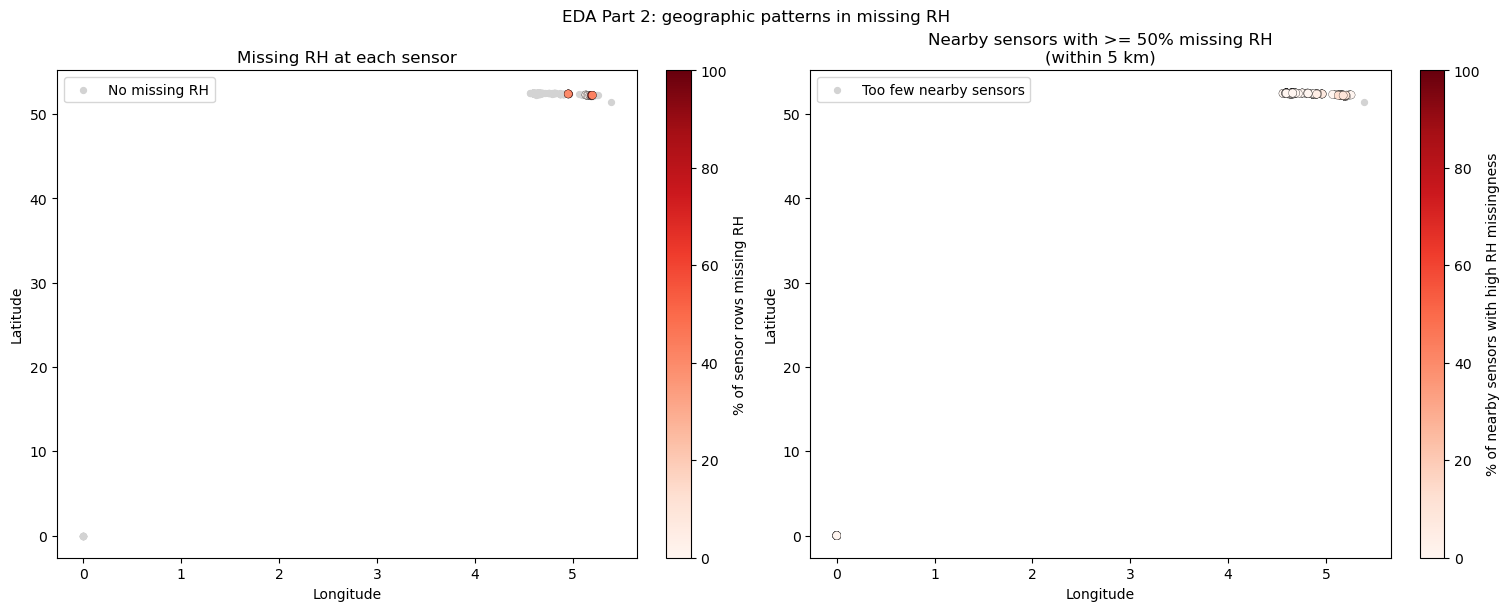


INTERPRETATION
- The left plot shows each sensor's own fraction of rows missing RH.
- The right plot shows the fraction of nearby sensors above the high-missingness threshold.
- Compare local percentages and missing-row counts with the dataset-wide baseline.
- Selected neighborhoods do not share sensors, but the full neighborhood table overlaps; do not add its rows together.
- Locations are sensor averages; excluded sensors and invalid coordinates can affect conclusions.
- This is descriptive: it does not test whether clustering is statistically significant.
- Results pool all times. Before dropping rows, check whether affected sensors overlap in time and whether regional coverage would be lost.
- No rows have been deleted or modified in the source file.


In [2]:
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from IPython.display import display

try:
    from sklearn.neighbors import BallTree
except ImportError as exc:
    raise ImportError(
        "This report needs scikit-learn. Install it with: pip install scikit-learn"
    ) from exc

# ============================================================
# EDA PART 2: WHERE IS RELATIVE HUMIDITY MISSING?
# ============================================================
# Focus: Are missing RH measurements concentrated geographically,
# and are many sensors within the same area affected?
# No rows are deleted or changed in the input Parquet file.

input_path = r"../data/data_sensors.parquet"  # relative to notebooks/
sensor_report_path = r"EDA_part_2_sensor_RH.csv"  # written next to this notebook
neighborhood_report_path = r"EDA_part_2_RH_neighborhoods.csv"
selected_report_path = r"EDA_part_2_selected_neighborhoods.csv"
members_report_path = r"EDA_part_2_selected_neighborhood_members.csv"

batch_size = 250_000

# Exploratory settings, NOT objectively correct cutoffs.
# Repeat the analysis with other radii (e.g. 2, 5, and 10 km).
radius_km = 5.0
min_sensors_per_neighborhood = 3  # includes the center sensor
high_missing_threshold_pct = 50.0  # >= this % of a sensor's rows missing RH
max_location_spread_km = 1.0  # exclude uncertain / potentially moving sensors
max_selected_neighborhoods = 20

if radius_km <= 0 or max_location_spread_km < 0:
    raise ValueError("radius_km must be positive and max_location_spread_km nonnegative.")
if min_sensors_per_neighborhood < 1 or max_selected_neighborhoods < 1:
    raise ValueError("Neighborhood limits must be at least 1.")
if not 0 <= high_missing_threshold_pct <= 100:
    raise ValueError("high_missing_threshold_pct must be between 0 and 100.")

required_columns = ["kit_id", "rh", "latitude", "longitude"]
parquet = pq.ParquetFile(input_path)
missing_columns = sorted(set(required_columns) - set(parquet.schema_arrow.names))
if missing_columns:
    raise ValueError(
        f"Columns not found: {missing_columns}. "
        f"Available columns: {parquet.schema_arrow.names}"
    )

# ============================================================
# 1. SENSOR-LEVEL SUMMARIES
# ============================================================
# Missing RH means a null, non-numeric value, or infinity. This does not
# test whether a finite RH reading is physically plausible.
print("EDA PART 2: summarizing relative humidity and sensor locations...")
sensor_parts = []
rows_processed = 0

for batch in parquet.iter_batches(batch_size=batch_size, columns=required_columns):
    chunk = batch.to_pandas()
    chunk["kit_id"] = chunk["kit_id"].astype("string")
    for col in ["rh", "latitude", "longitude"]:
        chunk[col] = pd.to_numeric(chunk[col], errors="coerce").astype(float)

    chunk["missing_rh"] = ~np.isfinite(chunk["rh"])
    valid_coords = (
        chunk["latitude"].between(-90, 90)
        & chunk["longitude"].between(-180, 180)
    )
    chunk["valid_coordinate"] = valid_coords.astype(int)
    chunk["lat_valid"] = chunk["latitude"].where(valid_coords)
    chunk["lon_valid"] = chunk["longitude"].where(valid_coords)

    # Preserve the missing-ID group for overall counts, but exclude it
    # from the sensor-level neighborhood analysis later.
    part = chunk.groupby("kit_id", dropna=False).agg(
        total_rows=("missing_rh", "size"),
        missing_rh_rows=("missing_rh", "sum"),
        valid_coordinate_rows=("valid_coordinate", "sum"),
        latitude_sum=("lat_valid", "sum"),
        longitude_sum=("lon_valid", "sum"),
        latitude_min=("lat_valid", "min"),
        latitude_max=("lat_valid", "max"),
        longitude_min=("lon_valid", "min"),
        longitude_max=("lon_valid", "max"),
    ).reset_index()
    sensor_parts.append(part)
    rows_processed += len(chunk)
    print(f"\rProcessed {rows_processed:,} rows", end="", flush=True)

print("\n")
if not sensor_parts:
    raise ValueError("No rows were found in the Parquet file.")

parts = pd.concat(sensor_parts, ignore_index=True)
sensors = parts.groupby("kit_id", dropna=False, as_index=False).agg(
    total_rows=("total_rows", "sum"),
    missing_rh_rows=("missing_rh_rows", "sum"),
    valid_coordinate_rows=("valid_coordinate_rows", "sum"),
    latitude_sum=("latitude_sum", "sum"),
    longitude_sum=("longitude_sum", "sum"),
    latitude_min=("latitude_min", "min"),
    latitude_max=("latitude_max", "max"),
    longitude_min=("longitude_min", "min"),
    longitude_max=("longitude_max", "max"),
)
del parts, sensor_parts

coordinate_count = sensors["valid_coordinate_rows"].replace(0, np.nan)
sensors["latitude"] = sensors["latitude_sum"] / coordinate_count
sensors["longitude"] = sensors["longitude_sum"] / coordinate_count
sensors["missing_rh_pct"] = 100 * sensors["missing_rh_rows"] / sensors["total_rows"]
sensors["has_any_missing_rh"] = sensors["missing_rh_rows"] > 0
sensors["high_missing_rh"] = (
    sensors["has_any_missing_rh"]
    & (sensors["missing_rh_pct"] >= high_missing_threshold_pct)
)

# Approximate the diagonal of each sensor's coordinate bounding rectangle.
# This is a rough location-consistency check, not a travel-distance estimate.
# Longitudes spanning the antimeridian are excluded because ordinary means
# and min/max ranges are not suitable for them.
def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = [np.radians(np.asarray(x, dtype=float)) for x in (lat1, lon1, lat2, lon2)]
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    return 6371.0088 * 2 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))

sensors["location_spread_km"] = haversine_km(
    sensors["latitude_min"], sensors["longitude_min"],
    sensors["latitude_max"], sensors["longitude_max"],
)
antimeridian_span = (sensors["longitude_max"] - sensors["longitude_min"]) > 180
sensors["spatial_status"] = "eligible"
sensors.loc[sensors["kit_id"].isna(), "spatial_status"] = "missing sensor ID"
sensors.loc[
    sensors["kit_id"].notna() & (sensors["valid_coordinate_rows"] == 0),
    "spatial_status",
] = "no valid coordinates"
sensors.loc[
    sensors["kit_id"].notna() & (sensors["valid_coordinate_rows"] > 0) & antimeridian_span,
    "spatial_status",
] = "longitude spans antimeridian"
sensors.loc[
    sensors["kit_id"].notna() & (sensors["valid_coordinate_rows"] > 0)
    & ~antimeridian_span & (sensors["location_spread_km"] > max_location_spread_km),
    "spatial_status",
] = "location spread too large"

sensors = sensors.drop(columns=["latitude_sum", "longitude_sum"])
sensors.to_csv(sensor_report_path, index=False)

# Overall missingness includes rows without an ID or usable coordinates.
total_rows = int(sensors["total_rows"].sum())
missing_rows = int(sensors["missing_rh_rows"].sum())
known = sensors[sensors["kit_id"].notna()]
eligible = sensors[sensors["spatial_status"] == "eligible"].copy().reset_index(drop=True)
eligible_missing_rows = int(eligible["missing_rh_rows"].sum())

print("=" * 70)
print("EDA PART 2: RELATIVE HUMIDITY MISSINGNESS")
print("=" * 70)
print(f"Total rows:                        {total_rows:,}")
print(f"Rows missing RH:                   {missing_rows:,} ({100 * missing_rows / total_rows:.2f}% of all rows)")
print(f"Known sensor IDs:                  {len(known):,}")
print(f"Known sensors with any missing RH: {int(known['has_any_missing_rh'].sum()):,}")
print(f"Known sensors with >= {high_missing_threshold_pct:g}% missing RH: {int(known['high_missing_rh'].sum()):,}")
print(f"Sensors eligible for spatial analysis: {len(eligible):,}")
print(f"Missing-RH rows from eligible sensors: {eligible_missing_rows:,} "
      f"({100 * eligible_missing_rows / missing_rows if missing_rows else 0:.2f}% of all missing-RH rows)")
print("\nSensor groups / rows excluded from spatial analysis:")
display(sensors.groupby("spatial_status", dropna=False).agg(
    sensor_id_groups=("spatial_status", "size"),
    total_rows=("total_rows", "sum"),
    missing_rh_rows=("missing_rh_rows", "sum"),
).reset_index())
print(f"Sensor-level report saved to: {sensor_report_path}")

if eligible.empty:
    raise ValueError("No sensors have a usable ID and sufficiently stable coordinates for spatial analysis.")

# ============================================================
# 2. NEIGHBORHOODS: A RADIUS AROUND EVERY ELIGIBLE SENSOR
# ============================================================
# Haversine distance is approximate distance on a spherical Earth.
# The center sensor counts as part of its own neighborhood.
coords_rad = np.radians(eligible[["latitude", "longitude"]].to_numpy(dtype=float))
tree = BallTree(coords_rad, metric="haversine")
neighbor_indices = tree.query_radius(coords_rad, r=radius_km / 6371.0088)

local_sensors = np.array([len(idx) for idx in neighbor_indices], dtype=int)
local_total_rows = np.array([int(eligible.iloc[idx]["total_rows"].sum()) for idx in neighbor_indices])
local_missing_rows = np.array([int(eligible.iloc[idx]["missing_rh_rows"].sum()) for idx in neighbor_indices])
local_any_missing = np.array([int(eligible.iloc[idx]["has_any_missing_rh"].sum()) for idx in neighbor_indices])
local_high_missing = np.array([int(eligible.iloc[idx]["high_missing_rh"].sum()) for idx in neighbor_indices])

neighborhoods = pd.DataFrame({
    "center_kit_id": eligible["kit_id"],
    "center_latitude": eligible["latitude"],
    "center_longitude": eligible["longitude"],
    "radius_km": radius_km,
    "sensor_count": local_sensors,
    "sensors_with_any_missing": local_any_missing,
    "pct_sensors_with_any_missing": 100 * local_any_missing / local_sensors,
    "sensors_high_missing": local_high_missing,
    "pct_sensors_high_missing": 100 * local_high_missing / local_sensors,
    "total_rows": local_total_rows,
    "missing_rh_rows": local_missing_rows,
    "pct_rows_missing_rh": 100 * local_missing_rows / local_total_rows,
    "pct_all_missing_rh_rows": (
        100 * local_missing_rows / missing_rows if missing_rows else np.zeros(len(eligible))
    ),
    "meets_minimum_sensor_count": local_sensors >= min_sensors_per_neighborhood,
})
neighborhoods.to_csv(neighborhood_report_path, index=False)

print("\nNEIGHBORHOOD SETTINGS")
print(f"Radius: {radius_km:g} km; minimum sensor count: {min_sensors_per_neighborhood} (including center)")
print(f"High missingness: at least {high_missing_threshold_pct:g}% of a sensor's rows")
print(f"Dataset-wide missing RH: {100 * missing_rows / total_rows:.2f}% of rows")
print(f"Eligible sensors with any missing RH: {100 * eligible['has_any_missing_rh'].mean():.2f}%")
print(f"Eligible sensors with high missing RH: {100 * eligible['high_missing_rh'].mean():.2f}%")
print("Each neighborhood is a circle around a sensor; neighborhoods overlap.")
print("A high local percentage indicates concentration to investigate, not proof of a cause.")

# ============================================================
# 3. SELECT NON-OVERLAPPING SENSOR SETS FOR INTERPRETATION
# ============================================================
# Greedy selection: prioritize neighborhoods containing the most missing
# RH rows. Skip a candidate if any of its sensors has already been selected.
# The circles themselves can still overlap geographically. This is an
# exploratory summary, not optimal clustering or an exhaustive partition.
candidate_indices = neighborhoods.index[
    neighborhoods["meets_minimum_sensor_count"] & (neighborhoods["missing_rh_rows"] > 0)
].tolist()
candidate_indices.sort(
    key=lambda i: (neighborhoods.at[i, "missing_rh_rows"], neighborhoods.at[i, "pct_sensors_high_missing"]),
    reverse=True,
)
used_sensor_indices = set()
selected_center_indices = []
for i in candidate_indices:
    members = set(map(int, neighbor_indices[i]))
    if members.isdisjoint(used_sensor_indices):
        selected_center_indices.append(i)
        used_sensor_indices.update(members)
        if len(selected_center_indices) >= max_selected_neighborhoods:
            break

selected = neighborhoods.iloc[selected_center_indices].copy().reset_index(drop=True)
selected.insert(0, "neighborhood_id", np.arange(1, len(selected) + 1))
selected.to_csv(selected_report_path, index=False)

member_parts = []
for neighborhood_id, center_index in enumerate(selected_center_indices, start=1):
    member = eligible.iloc[neighbor_indices[center_index]][[
        "kit_id", "latitude", "longitude", "total_rows", "missing_rh_rows",
        "missing_rh_pct", "has_any_missing_rh", "high_missing_rh",
    ]].copy()
    member.insert(0, "neighborhood_id", neighborhood_id)
    member["distance_to_center_km"] = haversine_km(
        eligible.at[center_index, "latitude"], eligible.at[center_index, "longitude"],
        member["latitude"], member["longitude"],
    )
    member_parts.append(member)

member_columns = [
    "neighborhood_id", "kit_id", "latitude", "longitude", "total_rows",
    "missing_rh_rows", "missing_rh_pct", "has_any_missing_rh", "high_missing_rh",
    "distance_to_center_km",
]
members = pd.concat(member_parts, ignore_index=True) if member_parts else pd.DataFrame(columns=member_columns)
members.to_csv(members_report_path, index=False)

selected_missing = int(selected["missing_rh_rows"].sum()) if not selected.empty else 0
print("\nSELECTED NEIGHBORHOODS (non-overlapping sensor memberships)")
print(f"Selected neighborhoods: {len(selected)}")
print(f"Missing-RH rows in selected neighborhoods: {selected_missing:,} "
      f"({100 * selected_missing / missing_rows if missing_rows else 0:.2f}% of all missing-RH rows)")
if selected.empty:
    print("No qualifying neighborhood contains missing RH. Consider changing the radius or minimum sensor count.")
else:
    display(selected[[
        "neighborhood_id", "center_kit_id", "center_latitude", "center_longitude",
        "sensor_count", "sensors_with_any_missing", "pct_sensors_with_any_missing",
        "sensors_high_missing", "pct_sensors_high_missing", "missing_rh_rows",
        "pct_rows_missing_rh", "pct_all_missing_rh_rows",
    ]])
print(f"All neighborhoods: {neighborhood_report_path}")
print(f"Selected neighborhoods: {selected_report_path}")
print(f"Selected neighborhood sensor membership: {members_report_path}")

# ============================================================
# 4. GEOGRAPHIC SCATTERPLOTS
# ============================================================
# These show coordinates only; no geographic basemap is used.
fig, axes = plt.subplots(1, 2, figsize=(15, 6), constrained_layout=True)

# Left: sensor-level fraction of rows missing RH.
complete = eligible[eligible["missing_rh_rows"] == 0]
affected = eligible[eligible["missing_rh_rows"] > 0]
if not complete.empty:
    axes[0].scatter(complete["longitude"], complete["latitude"], c="lightgrey", s=18, label="No missing RH")
if not affected.empty:
    points = axes[0].scatter(
        affected["longitude"], affected["latitude"], c=affected["missing_rh_pct"],
        cmap="Reds", vmin=0, vmax=100, s=35, edgecolors="black", linewidths=0.2,
    )
    fig.colorbar(points, ax=axes[0], label="% of sensor rows missing RH")
if not complete.empty:
    axes[0].legend(loc="best")
axes[0].set_title("Missing RH at each sensor")

# Right: equal-sensor-weighted local coverage of high missingness.
enough = neighborhoods["meets_minimum_sensor_count"]
if (~enough).any():
    axes[1].scatter(
        neighborhoods.loc[~enough, "center_longitude"], neighborhoods.loc[~enough, "center_latitude"],
        c="lightgrey", s=18, label="Too few nearby sensors",
    )
if enough.any():
    points = axes[1].scatter(
        neighborhoods.loc[enough, "center_longitude"], neighborhoods.loc[enough, "center_latitude"],
        c=neighborhoods.loc[enough, "pct_sensors_high_missing"], cmap="Reds", vmin=0, vmax=100,
        s=35, edgecolors="black", linewidths=0.2,
    )
    fig.colorbar(points, ax=axes[1], label="% of nearby sensors with high RH missingness")
if (~enough).any():
    axes[1].legend(loc="best")
axes[1].set_title(f"Nearby sensors with >= {high_missing_threshold_pct:g}% missing RH\n(within {radius_km:g} km)")

for ax in axes:
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
fig.suptitle("EDA Part 2: geographic patterns in missing RH")
plt.show()

print("\nINTERPRETATION")
print("- The left plot shows each sensor's own fraction of rows missing RH.")
print("- The right plot shows the fraction of nearby sensors above the high-missingness threshold.")
print("- Compare local percentages and missing-row counts with the dataset-wide baseline.")
print("- Selected neighborhoods do not share sensors, but the full neighborhood table overlaps; do not add its rows together.")
print("- Locations are sensor averages; excluded sensors and invalid coordinates can affect conclusions.")
print("- This is descriptive: it does not test whether clustering is statistically significant.")
print("- Results pool all times. Before dropping rows, check whether affected sensors overlap in time and whether regional coverage would be lost.")
print("- No rows have been deleted or modified in the source file.")